In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from numpy import random
import os
import time

from tensorflow.keras import layers, Model
from tensorflow.keras.layers import Flatten, Input, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split

In [2]:
# Muestra el nombre exacto de la GPU (prueba para ver si la detecta correctamente)
os.system("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader")

NVIDIA GeForce RTX 5060 Laptop GPU, 8151 MiB


0

In [3]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"¿GPU disponible?: Sí ({len(gpus)} detectada(s))")
    for i, gpu in enumerate(gpus):
        # Obtener los detalles del dispositivo
        details = tf.config.experimental.get_device_details(gpu)
        device_name = details.get('device_name', 'Nombre desconocido')
        print(f"  - GPU {i}: {device_name} ({gpu.name})")
else:
    print("¿GPU disponible?: No (Usando CPU)")


print("Lanzando prueba en GPU...")
time.sleep(0.5)
if tf.config.list_physical_devices('GPU'):
    # Crear un tensor explícitamente en la GPU
    with tf.device('/GPU:0'):
        a = tf.constant([[1.0, 2.0], [3.0, 4.0]])
        b = tf.constant([[1.0, 1.0], [0.0, 1.0]])
        c = tf.matmul(a, b)
    print(f"Prueba ejecutada correctamente en: {c.device}")

¿GPU disponible?: Sí (1 detectada(s))
  - GPU 0: NVIDIA GeForce RTX 5060 Laptop GPU (/physical_device:GPU:0)
Lanzando prueba en GPU...
Prueba ejecutada correctamente en: /job:localhost/replica:0/task:0/device:GPU:0


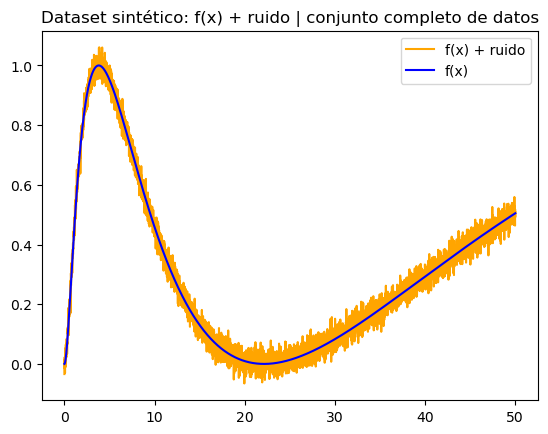

In [4]:
# 1. Creación de un dataset sintético
# Como queremos ver qué ocurre según el tamaño de la red, profundidad, número de neuronas, etc., el dataset es lo de menos.
# En particular, cuanto más sencillo sea el dataset, más fácil para nosotros será esperar ciertos comportamientos, y las dificultades de entrenamiento serán más evidentes.

# Dataset: creemos una función no lineal, creemos unas etiquetas que tengan algo de ruido (los datos reales nunca son perfectos),y entrenemos a una red neuronal para que sea capaz de aproximar esta función.

x_ordered       = np.linspace(0, 50, 5000)
y_clean_ordered = np.sin(np.log(1 + x_ordered))**2
y_noise_ordered = y_clean_ordered + random.normal(0, 0.025, size=x_ordered.shape)
shuffle         = False 


if shuffle:
    # remezclar los datos (manteniendo la correspondencia entre x e y)
    indices_permutados = np.random.permutation(len(x_ordered))
    x = x_ordered[indices_permutados]
    y_clean = y_clean_ordered[indices_permutados]
    y_noise = y_noise_ordered[indices_permutados]

    # train | val | test
    x_train, x_test, y_train, y_test = train_test_split(x, y_noise, test_size=0.2, random_state=42)
    x_val, x_test, y_val, y_test = train_test_split(x_test, y_test, test_size=0.5, random_state=42)
else:
    x_train = x_ordered[:4000]
    y_train = y_noise_ordered[:4000]
    x_val = x_ordered[4000:4500]
    y_val = y_noise_ordered[4000:4500]
    x_test = x_ordered[4500:]
    y_test = y_noise_ordered[4500:]

# implementamos los datos en un dataset de TensorFlow para ganar eficiencia en el entrenamiento
batch_size = int(32)
data_train = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(buffer_size=1024).batch(batch_size)
data_val = tf.data.Dataset.from_tensor_slices((x_val, y_val)).shuffle(buffer_size=1024).batch(batch_size)
data_test = tf.data.Dataset.from_tensor_slices((x_test, y_test)).shuffle(buffer_size=1024).batch(batch_size)




plt.plot(x_ordered, y_noise_ordered, label='f(x) + ruido', color='orange')
plt.plot(x_ordered, y_clean_ordered, label='f(x)', color='blue')
plt.legend()
plt.title('Dataset sintético: f(x) + ruido | conjunto completo de datos')
plt.show()

In [5]:
# 2. Creamos la función "creadora" de redes neuronales, que nos permitirá crear redes de diferentes tamaños y profundidades.

# Todas ellas las vamos a basar en una red fully conected (MLP)

def create_nn(num_layers, neurons_0, architecture='reducing', reduce_factor=0.5, activation='relu', lr=0.001):

    input_layer = Input(shape=(1,))
    x = input_layer

    for layer in range(num_layers):
        if layer == 0:
            neurons = neurons_0
        else:
            if architecture == 'reducing':
                neurons = int(neurons * reduce_factor)
            elif architecture == 'increasing':
                neurons = int(neurons / reduce_factor)
            elif architecture == 'constant':
                neurons = neurons_0
        x = Dense(neurons, activation=activation)(x)

    output_layer = Dense(1, activation='linear')(x)
    
    model = Model(inputs=input_layer, outputs=output_layer)
    optimizer_SGD = tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.5)
    model.compile(optimizer=optimizer_SGD, loss='mse', metrics=['mae'])
    return model


In [12]:
# Realizamos la comparación entre entrenamientos de tres redes de tamaño diferente. Criterios que comprobaremos:
# - ¿Mayor tiempo de entrenamiento (mismo número de epochs, sin early stopping)?
# - ¿Cuál de las tres redes es capaz de aproximar mejor la función ln(1+x)? (conjunto de test)
# - ¿Ocurre overfitting con la red más grande? ¿O underfitting con la red más pequeña? ¿Cuál de las tres redes es capaz de generalizar mejor?
# - Comparación de las curvas de entrenamiento: ¿Cuál de las tres redes aprende más rápido (converge antes)?
# - ¿Vemos algún fenómeno de saturación (e.g. vanishing gradient)?

modelo_enorme = create_nn(num_layers=12, neurons_0=800, architecture='constant', reduce_factor=1, activation='relu')
modelo_mediano = create_nn(num_layers=4, neurons_0=64, architecture='reducing', reduce_factor=0.5, activation='relu')
modelo_pequeño = create_nn(num_layers=2, neurons_0=8, architecture='reducing', reduce_factor=0.5, activation='relu')


In [13]:
num_epochs = 250

t_enorme_start = time.time()
modelo_enorme.fit(
    data_train,
    validation_data=data_val,
    epochs=num_epochs,
    verbose=0
)
t_enorme_end = time.time()
print("Entrenamiento sobre la red enorme terminado en: ", t_enorme_end - t_enorme_start, " segundos")

t_mediano_start = time.time()
modelo_mediano.fit(
    data_train,
    validation_data=data_val,
    epochs=num_epochs,
    verbose=0
)
t_mediano_end = time.time()
print("Entrenamiento sobre la red mediana terminado en: ", t_mediano_end - t_mediano_start, " segundos")

t_pequeño_start = time.time()
modelo_pequeño.fit(
    data_train,
    validation_data=data_val,
    epochs=num_epochs,
    verbose=0
)
t_pequeño_end = time.time()
print("Entrenamiento sobre la red pequeña terminado en: ", t_pequeño_end - t_pequeño_start, " segundos")

/home/samuel/miniforge3/envs/Master_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Entrenamiento sobre la red enorme terminado en:  62.228086948394775  segundos
Entrenamiento sobre la red mediana terminado en:  32.3544340133667  segundos
Entrenamiento sobre la red pequeña terminado en:  31.91902256011963  segundos


In [14]:
# Diagnóstico de los modelos
tiempo_entrenamiento_enorme = t_enorme_end - t_enorme_start
tiempo_entrenamiento_mediano = t_mediano_end - t_mediano_start
tiempo_entrenamiento_pequeño = t_pequeño_end - t_pequeño_start

mae_test_enorme = modelo_enorme.evaluate(x_test, y_test, verbose=0)[1]
mae_test_mediano = modelo_mediano.evaluate(x_test, y_test, verbose=0)[1]
mae_test_pequeño = modelo_pequeño.evaluate(x_test, y_test, verbose=0)[1]

mse_test_enorme = modelo_enorme.evaluate(x_test, y_test, verbose=0)[0]
mse_test_mediano = modelo_mediano.evaluate(x_test, y_test, verbose=0)[0]
mse_test_pequeño = modelo_pequeño.evaluate(x_test, y_test, verbose=0)[0]

# tabla comparativa
comparativa = pd.DataFrame({
    'Modelo': ['Enorme', 'Mediano', 'Pequeño'],
    'Tiempo de Entrenamiento (s)': [tiempo_entrenamiento_enorme, tiempo_entrenamiento_mediano, tiempo_entrenamiento_pequeño],
    'MAE Test': [mae_test_enorme, mae_test_mediano, mae_test_pequeño],
    'MSE Test': [mse_test_enorme, mse_test_mediano, mse_test_pequeño]
})

comparativa

,Modelo,Tiempo de Entrenamiento (s),MAE Test,MSE Test
0,Enorme,62.228087,0.049637,0.003007
1,Mediano,32.354434,0.065261,0.004884
2,Pequeño,31.919023,0.482631,0.235941


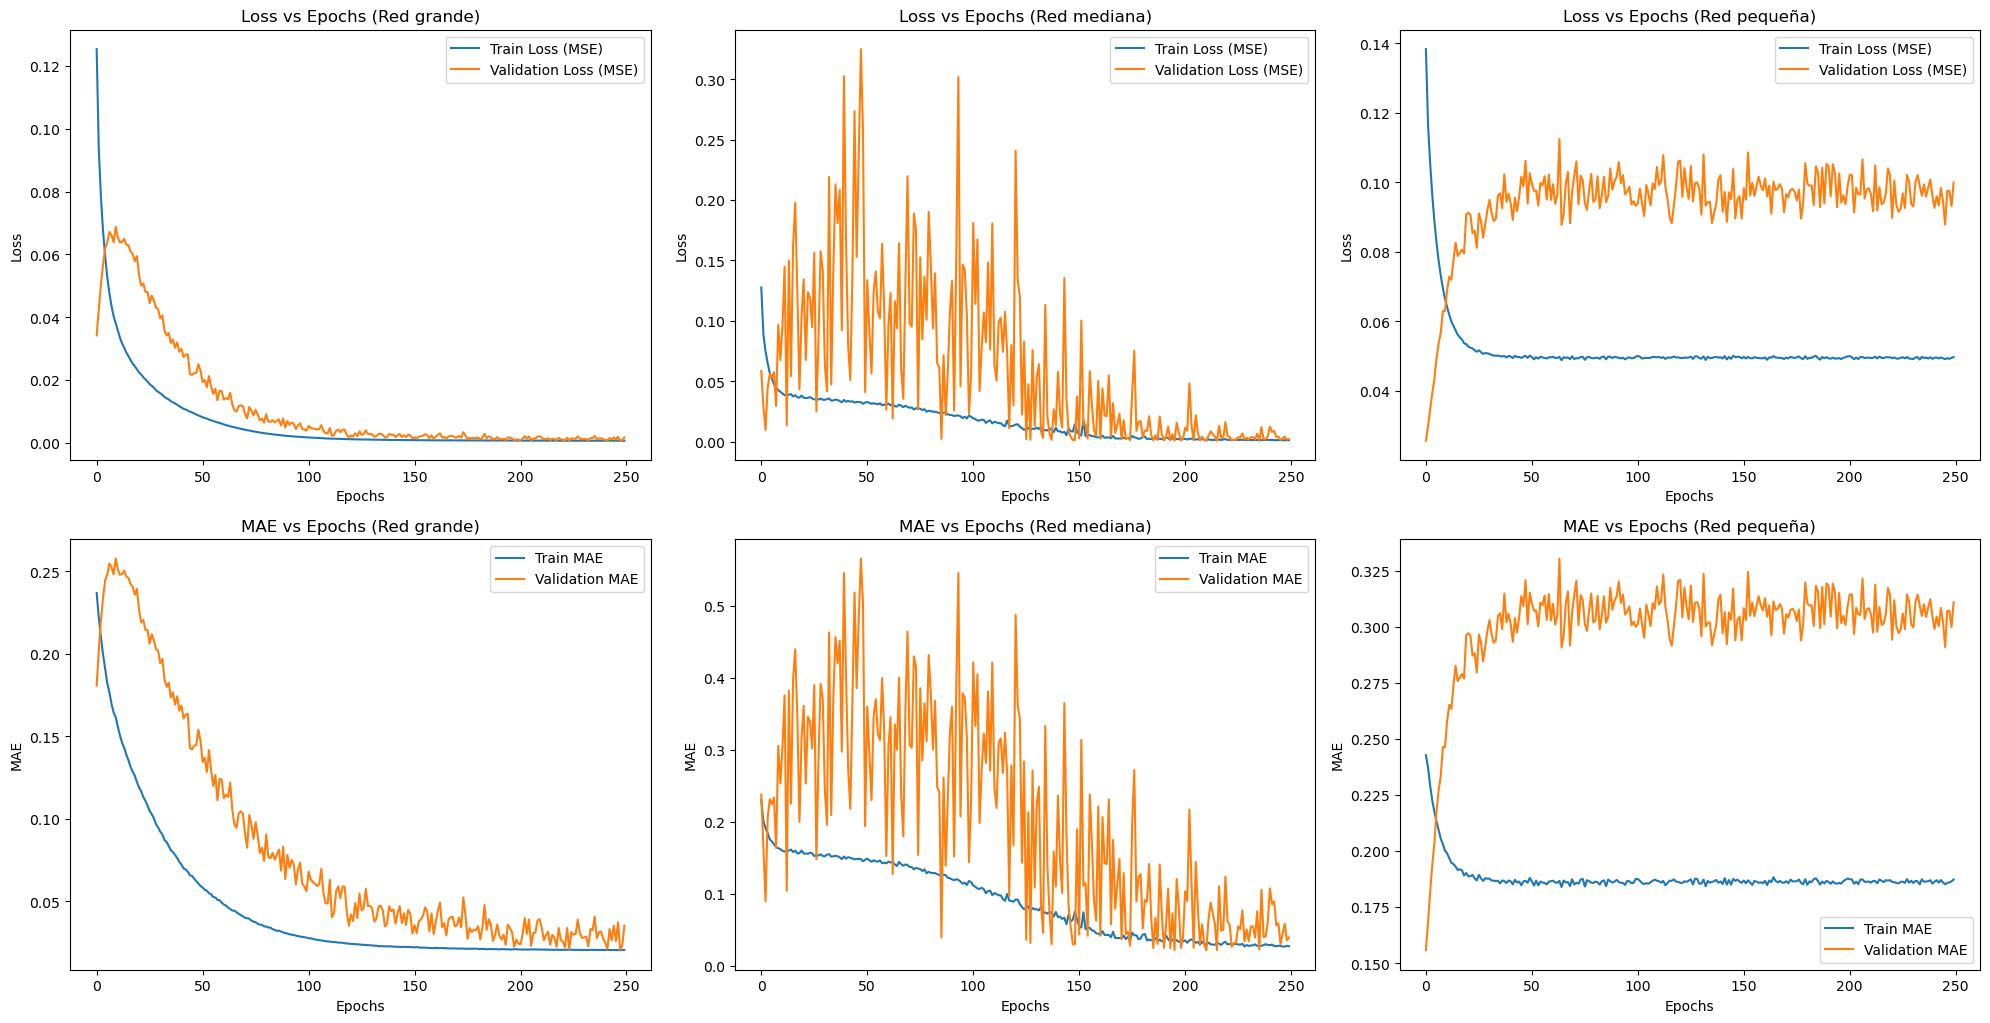

In [15]:
history_enorme = modelo_enorme.history.history
history_mediano = modelo_mediano.history.history
history_pequeño = modelo_pequeño.history.history

plt.figure(figsize=(20, 15))
plt.subplot(3, 3, 1)
plt.title('Loss vs Epochs (Red grande)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.plot(history_enorme['loss'], label='Train Loss (MSE)')
plt.plot(history_enorme['val_loss'], label='Validation Loss (MSE)')
plt.legend()

plt.subplot(3, 3, 2)
plt.title('Loss vs Epochs (Red mediana)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.plot(history_mediano['loss'], label='Train Loss (MSE)')
plt.plot(history_mediano['val_loss'], label='Validation Loss (MSE)')
plt.legend()

plt.subplot(3, 3, 3)
plt.title('Loss vs Epochs (Red pequeña)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.plot(history_pequeño['loss'], label='Train Loss (MSE)')
plt.plot(history_pequeño['val_loss'], label='Validation Loss (MSE)')
plt.legend()

plt.subplot(3, 3, 4)
plt.title('MAE vs Epochs (Red grande)')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.plot(history_enorme['mae'], label='Train MAE')
plt.plot(history_enorme['val_mae'], label='Validation MAE')
plt.legend()

plt.subplot(3, 3, 5)
plt.title('MAE vs Epochs (Red mediana)')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.plot(history_mediano['mae'], label='Train MAE')
plt.plot(history_mediano['val_mae'], label='Validation MAE')
plt.legend()

plt.subplot(3, 3, 6)
plt.title('MAE vs Epochs (Red pequeña)')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.plot(history_pequeño['mae'], label='Train MAE')
plt.plot(history_pequeño['val_mae'], label='Validation MAE')
plt.legend()
plt.tight_layout()
plt.show()

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 614us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 491us/step


<Figure size 1200x500 with 0 Axes>

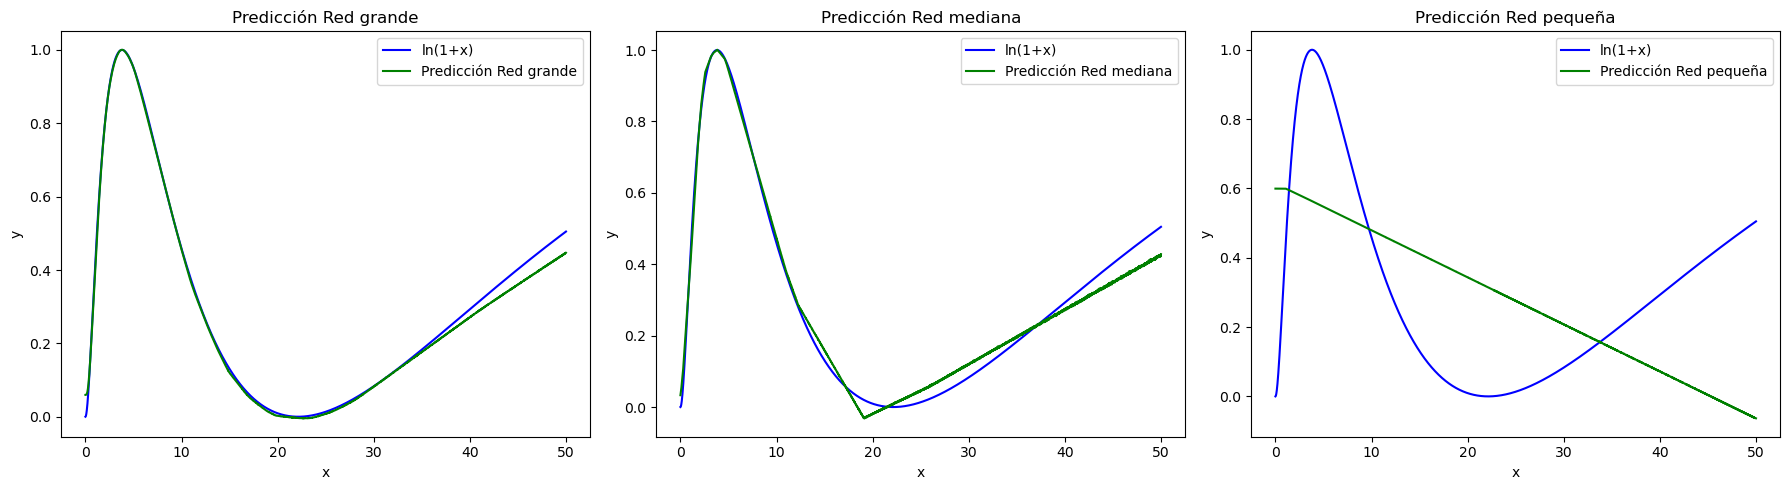

In [16]:
# gráfico de predicciones de ambos modelos

y_pred_enorme = modelo_enorme.predict(x_ordered)
y_pred_pequeño = modelo_pequeño.predict(x_ordered)
plt.figure(figsize=(12, 5))
# Gráfico de predicciones de los tres modelos

y_pred_enorme = modelo_enorme.predict(x_ordered)
y_pred_mediano = modelo_mediano.predict(x_ordered)
y_pred_pequeño = modelo_pequeño.predict(x_ordered)

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.title('Predicción Red grande')
plt.xlabel('x')
plt.ylabel('y')
plt.plot(x_ordered, y_clean_ordered, label='ln(1+x)', color='blue')
plt.plot(x_ordered, y_pred_enorme, label='Predicción Red grande', color='green')
plt.legend()

plt.subplot(1, 3, 2)
plt.title('Predicción Red mediana')
plt.xlabel('x')
plt.ylabel('y')
plt.plot(x_ordered, y_clean_ordered, label='ln(1+x)', color='blue')
plt.plot(x_ordered, y_pred_mediano, label='Predicción Red mediana', color='green')
plt.legend()

plt.subplot(1, 3, 3)
plt.title('Predicción Red pequeña')
plt.xlabel('x')
plt.ylabel('y')
plt.plot(x_ordered, y_clean_ordered, label='ln(1+x)', color='blue')
plt.plot(x_ordered, y_pred_pequeño, label='Predicción Red pequeña', color='green')
plt.legend()

plt.tight_layout()
plt.show()